# Synthetic Image Detection: CNN Baseline

## 1. Project Overview

This notebook develops a Convolutional Neural Network (CNN) from scratch to classify images as real or AI-generated using the CIFAKE dataset.

The experiment covers dataset exploration, preprocessing, CNN architecture, model training, and evaluation on unseen test data.

**Dataset:** CIFAKE — 100,000 training images and 20,000 test images, each with a resolution of 32 × 32 pixels.

In [1]:
from pathlib import Path
from PIL import Image
from sklearn.metrics import classification_report
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

## 2. Dataset Exploration

The CIFAKE dataset contains real images collected from CIFAR-10 and synthetic images generated by AI. Both classes contain 32 × 32 RGB images.

The training split contains 50,000 images per class, while the test split contains 10,000 images per class. This balanced distribution allows us to evaluate the model without one class dominating the dataset.

In [4]:
dataset_dir = Path('../dataset/archive')

real_images = list((dataset_dir/'train'/'REAL').glob('*.jpg'))
fake_images = list((dataset_dir/'train'/'FAKE').glob('*.jpg'))

print(f'Real images: {len(real_images)}')
print(f'Fake images: {len(fake_images)}')

Real images: 50000
Fake images: 50000


### Visualizing Sample Images

The following examples provide a visual comparison between real and AI-generated images. Because the images are only 32 × 32 pixels, some fine details may be difficult to distinguish.

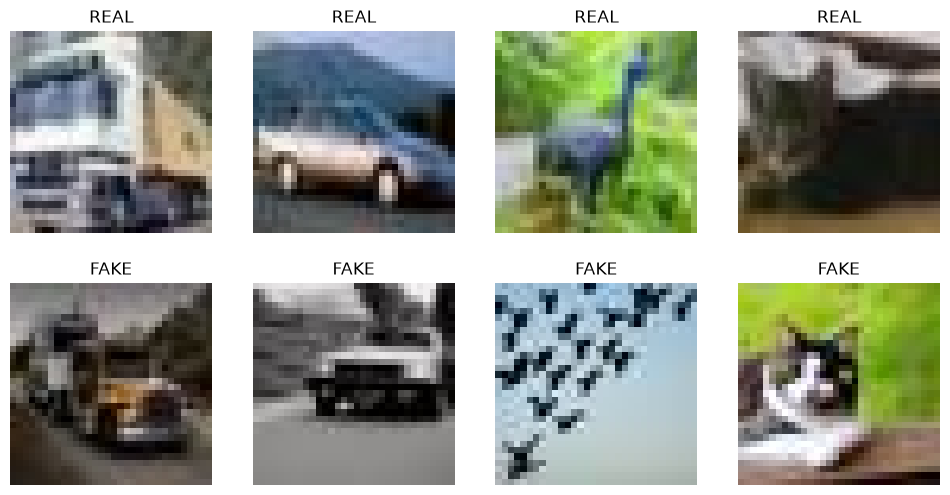

In [5]:
fig, axes = plt.subplots(2, 4, figsize = (12,6))

for i in range(4):
    axes[0, i].imshow(Image.open(real_images[i]))
    axes[0, i].set_title('REAL')
    axes[0, i].axis('off')

    axes[1, i].imshow(Image.open(fake_images[i]))
    axes[1, i].set_title('FAKE')
    axes[1, i].axis('off')

In [6]:
test_real = list((dataset_dir/'test'/'REAL').glob('*.jpg'))
test_fake = list((dataset_dir/'test'/'FAKE').glob('*.jpg'))

print(f'Real images: {len(test_real)}')
print(f'Fake images: {len(test_fake)}')

Real images: 10000
Fake images: 10000


In [7]:
sample_image = Image.open(real_images[0])

print(f'Image dimensions: {sample_image.size}')
print(f'Image mode: {sample_image.mode}')

Image dimensions: (32, 32)
Image mode: RGB


## 3. Data Loading and Preprocessing

The dataset is divided into training, validation, and test sets. The training set is used to learn model parameters, the validation set helps monitor performance during training, and the test set provides a final evaluation on unseen images.

In [8]:
train_dir = dataset_dir/'train'

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, validation_split = 0.2, subset = 'training', seed = 42, image_size = (32,32), batch_size = 32, label_mode = 'binary')
val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, validation_split = 0.2, subset = 'validation', seed = 42, image_size = (32,32), batch_size = 32, label_mode = 'binary')

Found 100000 files belonging to 2 classes.
Using 80000 files for training.
Found 100000 files belonging to 2 classes.
Using 20000 files for validation.


In [9]:
print(f'Class names: {train_ds.class_names}')

Class names: ['FAKE', 'REAL']


### 3.1 Image Normalization

Pixel values are rescaled from the range [0, 255] to [0, 1]. This provides a consistent numerical range for the neural network's inputs.

In [10]:
normalization_layer = tf.keras.layers.Rescaling(1/255)

train_ds = train_ds.map(lambda images, labels: (normalization_layer(images), labels))
val_ds = val_ds.map(lambda images, labels: (normalization_layer(images), labels))

In [11]:
images, labels = next(iter(train_ds))

print(f"Image batch shape: {images.shape}")
print(f"Label batch shape: {labels.shape}")

print(f'Pixel range: {tf.reduce_min(images).numpy()} to {tf.reduce_max(images).numpy()}')

Image batch shape: (32, 32, 32, 3)
Label batch shape: (32, 1)
Pixel range: 0.0 to 1.0


## 4. CNN Architecture

A Convolutional Neural Network is built from scratch using convolutional layers, max-pooling layers, a flattening layer, and dense layers.

Convolutional layers learn visual features, max pooling reduces spatial dimensions, and dense layers use the extracted features to classify each image as real or AI-generated.

In [12]:
model = tf.keras.Sequential([tf.keras.layers.Input(shape=(32,32,3)),  # Accepts 32×32 RGB images
                             tf.keras.layers.Conv2D(filters=32, kernel_size=(3,3),activation='relu')]) # Learns 32 filters to detect simple visual features
x = model(images)
print(f'Output shape: {x.shape}')

Output shape: (32, 30, 30, 32)


In [13]:
# Halves the spatial dimensions, keeping the strongest features in each 2×2 region
model.add(tf.keras.layers.MaxPooling2D(pool_size=(2,2)))
x = model(images)
print(f'Output shape: {x.shape}')

Output shape: (32, 15, 15, 32)


In [14]:
# Learns 64 filters that can combine simpler features into more complex patterns
model.add(tf.keras.layers.Conv2D(filters=64, kernel_size=(3,3), activation='relu'))
x = model(images)
print(f'Output shape: {x.shape}')

Output shape: (32, 13, 13, 64)


In [15]:
# Further reduces image dimensions and computational load
model.add(tf.keras.layers.MaxPooling2D(pool_size=(2,2)))
x = model(images)
print(f'Output shape: {x.shape}')

Output shape: (32, 6, 6, 64)


In [16]:
# Converts the 3D feature maps into a 1D vector for the dense layers
model.add(tf.keras.layers.Flatten())
x = model(images)
print(f'Output shape: {x.shape}')

Output shape: (32, 2304)


In [17]:
# Combines extracted features to learn patterns useful for classification
model.add(tf.keras.layers.Dense(64, activation='relu'))
x = model(images)
print(f'Output shape: {x.shape}')

Output shape: (32, 64)


In [18]:
# Produces a probability between 0 and 1 for the REAL class
# Values >= 0.5 are classified as REAL; values < 0.5 as FAKE
model.add(tf.keras.layers.Dense(1, activation='sigmoid'))
x = model(images)
print(f'Output shape: {x.shape}')

Output shape: (32, 1)


## 5. Model Training

The CNN is compiled using the Adam optimizer, binary cross-entropy loss, and accuracy as an evaluation metric.

The model is trained for 10 epochs using the training dataset, with validation performance monitored after each epoch.

In [19]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [20]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 30, 30, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 13, 13, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 2304)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │         147,520 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 166,977 (652.25 KB)

 Trainable params: 166,977 (652.25 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
history = model.fit(train_ds, validation_data = val_ds, epochs = 10)

Epoch 1/10


C:\Users\Onabanjo Daniel\AppData\Roaming\Python\Python314\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


2500/2500 ━━━━━━━━━━━━━━━━━━━━ 441s 175ms/step - accuracy: 0.8514 - loss: 0.3373 - val_accuracy: 0.9097 - val_loss: 0.2251
Epoch 2/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 86s 34ms/step - accuracy: 0.9083 - loss: 0.2246 - val_accuracy: 0.9238 - val_loss: 0.1975
Epoch 3/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 70s 28ms/step - accuracy: 0.9226 - loss: 0.1925 - val_accuracy: 0.9266 - val_loss: 0.1876
Epoch 4/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 71s 29ms/step - accuracy: 0.9326 - loss: 0.1718 - val_accuracy: 0.9276 - val_loss: 0.1874
Epoch 5/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 89s 35ms/step - accuracy: 0.9388 - loss: 0.1550 - val_accuracy: 0.9265 - val_loss: 0.1960
Epoch 6/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 144s 36ms/step - accuracy: 0.9456 - loss: 0.1394 - val_accuracy: 0.9347 - val_loss: 0.1783
Epoch 7/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 194s 78ms/step - accuracy: 0.9514 - loss: 0.1236 - val_accuracy: 0.9324 - val_loss: 0.1835
Epoch 8/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 67s 27ms/step - accuracy: 0.9567 - loss: 

### Learning Curves

Training and validation accuracy and loss are plotted across epochs to examine the model's learning progress and identify potential overfitting.

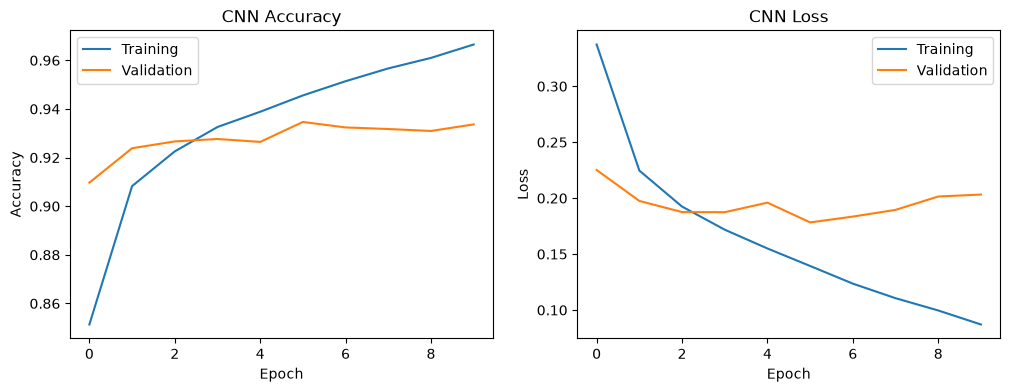

In [22]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label = 'Training')
plt.plot(history.history['val_accuracy'], label = 'Validation')
plt.title('CNN Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label = 'Training')
plt.plot(history.history['val_loss'], label = 'Validation')
plt.title('CNN Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

In [23]:
print(f"Training accuracy: {history.history["accuracy"][-1]}")
print(f"Validation accuracy: {history.history["val_accuracy"][-1]}")
print(f"Training loss: {history.history["loss"][-1]}")
print(f"Validation loss: {history.history["val_loss"][-1]}")

Training accuracy: 0.9665125012397766
Validation accuracy: 0.933650016784668
Training loss: 0.08707737922668457
Validation loss: 0.20320585370063782


## 6. Model Evaluation

The trained model is evaluated on a separate test set of 20,000 images that were not used for training or validation.

Accuracy and loss measure overall performance, while precision, recall, and F1-score provide a class-specific assessment of the model's ability to distinguish real images from AI-generated images.

In [24]:
test_dir = dataset_dir/'test'
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir, image_size =(32,32), batch_size=32, label_mode='binary', shuffle=False)
test_ds = test_ds.map(lambda images, labels: (normalization_layer(images), labels))

Found 20000 files belonging to 2 classes.


In [25]:
test_loss, test_accuracy = model.evaluate(test_ds)

print(f'Test accuracy: {test_accuracy}')
print(f'Test loss: {test_loss}')

625/625 ━━━━━━━━━━━━━━━━━━━━ 59s 94ms/step - accuracy: 0.9294 - loss: 0.2104
Test accuracy: 0.9294499754905701
Test loss: 0.21042616665363312


In [27]:
model.save("../models/cnn_baseline.keras")

In [28]:
y_true = np.concatenate([labels.numpy().ravel() for _, labels in test_ds])
y_prob = model.predict(test_ds, verbose = 1).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print(classification_report(y_true,y_pred, target_names=['FAKE','REAL']))

625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step
              precision    recall  f1-score   support

        FAKE       0.92      0.94      0.93     10000
        REAL       0.94      0.92      0.93     10000

    accuracy                           0.93     20000
   macro avg       0.93      0.93      0.93     20000
weighted avg       0.93      0.93      0.93     20000



## 7. Results and Discussion

The CNN achieved **92.94% test accuracy** on 20,000 previously unseen CIFAKE images, with a test loss of 0.2104.

The classification report showed:
- **FAKE precision:** 92%
- **FAKE recall:** 94%
- **REAL precision:** 94%
- **REAL recall:** 92%
- **Macro-average F1-score:** 93%

The model identifies 94% of AI-generated images and 92% of real images correctly, based on class-specific recall. Its precision scores indicate that 92% of images predicted as FAKE were actually fake, while 94% of images predicted as REAL were actually real.

Training accuracy was 96.65%, compared with validation accuracy of 93.37% and test accuracy of 92.94%. This gap suggests some overfitting, although the validation and test results are relatively close.

These results establish a baseline for comparison with a transfer-learning approach.

## 8. Limitations

This experiment uses 32 × 32 pixel images from the CIFAKE dataset. Its results may not generalize to images from other datasets, AI generators, or real-world sources.

The evaluation measures performance on this particular benchmark and should not be interpreted as proof that the model can reliably identify AI-generated images in general.